# 853. Car Fleet
**Difficulty:** 🟡 Medium · **Topic:** Stack · **Pattern:** [Monotonic Stack](README.md) · **LeetCode:** https://leetcode.com/problems/car-fleet/

## 💡 Concepts

**Core concept(s):** **Sort by position + a monotonic stack of arrival times.**

**Why it applies here:**
- Cars cannot pass each other. Whether a car ends up in a fleet depends only on the cars **ahead** of it, so process cars from the one **closest to the target** backwards.
- Turn each car into one number: the time it would need to reach the target alone, `(target - position) / speed`.
- A car that would arrive **no later** than the fleet just ahead of it catches that fleet (at or before the target) and merges into it. It adds no new fleet.
- A car that would arrive **later** can never catch anyone: it starts a new fleet. So, from front to back, fleet arrival times only ever **increase** — a monotonic stack.

**Key intuition:**
- Sort cars by position, closest to the target first.
- Keep a stack of fleet arrival times; the top is the fleet just ahead of the current car.
- Current time `<=` top: the car merges (push nothing). Current time `>` top: it is a new, slower fleet (push).
- The answer is the stack's length.

---

### 📚 What is Sorting?
- **Sorting** puts items in order so that later steps can rely on that order.
- Python's `sorted` (Timsort) runs in **O(n log n)** time and **O(n)** extra space.
- Sorting `(position, speed)` pairs orders them by position; `reverse=True` puts the car closest to the target first.
- **In Python:** `sorted(zip(position, speed), reverse=True)`.

### 📚 What is a Stack?
- A **stack** is a pile: you add (**push**) and remove (**pop**) only at the **top**.
- Last in, first out: the item pushed most recently is the first one popped.
- **Key operations:** push, pop, peek at the top — all **O(1)**.
- **In Python:** a plain `list` — `append` pushes, `pop()` pops, `stack[-1]` peeks.

### 📚 What is a Monotonic Stack?
- A **monotonic stack** is an ordinary stack with one rule: the values it holds stay **sorted** from bottom to top (always decreasing, or always increasing).
- Before pushing a new item, you **pop every item that would break the order**. Those pops are the useful part: the new item is the *answer* for each item it pops (its "next greater" or "next smaller" element).
- It usually stores **indices**, not values: the value is `arr[i]`, and the index gives distances and widths (`i - j`).
- **Complexity:** each index is pushed once and popped at most once, so a full pass is **O(n)** even though there is a `while` loop inside the `for` loop.
- **In Python:** a `list` used as a stack, plus the `while stack and <order broken>: stack.pop()` loop.

---

**Prerequisite knowledge:**
- Time = distance / speed.
- [Daily Temperatures](daily_temperatures.ipynb): the same stack, with the "next greater" rule.

## 📝 Problem

`n` cars drive along a one-lane road towards `target` (miles). Car `i` starts at `position[i]` with speed `speed[i]` (miles per hour).

- A car can never pass another car. If a faster car catches a slower one, it slows down and they drive together as one **car fleet** at the slower speed.
- A single car is also a fleet.
- If a car catches a fleet **exactly at the target**, it still counts as part of that fleet.

Return the **number of car fleets** that arrive at the target.

**Example 1**
```
target = 12, position = [10, 8, 0, 5, 3], speed = [2, 4, 1, 1, 3]  ->  3

car at 10 (speed 2) arrives at t = 1;  car at 8 (speed 4) also at t = 1  -> they meet at 12: one fleet
car at 5  (speed 1) arrives at t = 7;  car at 3 (speed 3) would arrive at t = 3, catches it -> one fleet
car at 0  (speed 1) arrives at t = 12: alone                                             -> one fleet
```

**Example 2:** `target = 10, position = [3], speed = [3]` → `1`

**Example 3:** `target = 100, position = [0, 2, 4], speed = [4, 2, 1]` → `1` (all three meet before 100)

**Constraints:** `1 <= n <= 10^5`, `0 < target <= 10^6`, `0 <= position[i] < target`, all positions are **unique**, `0 < speed[i] <= 10^6`.

> Two approaches: a brute-force "is anyone ahead slower?" check for every car (`O(n²)`), then sort + monotonic stack (`O(n log n)`, the pattern template).

In [1]:
from typing import List

### Approach 1 — Brute Force: for every car, look at every car ahead

**Idea:**
1. Compute each car's solo arrival time `time[i] = (target - position[i]) / speed[i]`.
2. Car `i` ends up stuck behind someone exactly when **some car ahead of it would arrive no earlier** (`time[j] >= time[i]`): it catches that car, or the fleet that car is stuck in, at or before the target.
3. Otherwise car `i` is the **front car of its own fleet**. Count those cars.

**Time complexity:** `O(n²)` — each car checks every other car.

**Space complexity:** `O(n)` — the `time` list.

In [2]:
def car_fleet_brute(target: int, position: List[int], speed: List[int]) -> int:
    n = len(position)
    time = [(target - p) / s for p, s in zip(position, speed)]   # solo arrival time of each car
    fleets = 0
    for i in range(n):
        # blocked = some car AHEAD of i arrives no earlier, so i catches it (or its fleet) by the target
        blocked = any(position[j] > position[i] and time[j] >= time[i] for j in range(n))
        if not blocked:
            fleets += 1                        # i is the front car of a fleet
    return fleets

### Approach 2 — Sort by position + monotonic stack of arrival times (optimal · pattern template)

**Idea:** the [Monotonic Stack](README.md) template on arrival times, read from the front of the road to the back.
1. Sort the cars by position, **closest to the target first**.
2. Keep a stack of fleet arrival times. The top is the fleet directly ahead of the current car.
3. For each car, compute its solo time `t`.
   - `t <= stack[-1]`: it would arrive no later than the fleet ahead, so it catches it and merges. Push nothing.
   - `t > stack[-1]` (or the stack is empty): it can never catch the fleet ahead. Push `t` as a new fleet.
4. The stack's times strictly increase from bottom to top; its length is the number of fleets.

**Time complexity:** `O(n log n)` — the sort dominates; the stack pass is `O(n)`.

**Space complexity:** `O(n)` — the sorted list and the stack.

> NeetCode writes the same idea as "push `t`, then pop it if `stack[-1] <= stack[-2]`". Here the car that would break the increasing order is simply not pushed. Because the loop only ever reads the top, the stack could even be a single "slowest time so far" variable; the stack form keeps the pattern visible.

In [3]:
def car_fleet_stack(target: int, position: List[int], speed: List[int]) -> int:
    cars = sorted(zip(position, speed), reverse=True)   # closest to the target first
    stack = []                                          # fleet arrival times, strictly increasing bottom -> top
    for p, s in cars:
        t = (target - p) / s                            # this car's solo arrival time
        if not stack or t > stack[-1]:                  # slower than the fleet just ahead: can never catch it
            stack.append(t)                             # -> a new fleet
        # else: t <= stack[-1], it catches the fleet ahead at or before the target and merges
    return len(stack)

In [4]:
# Correctness check
import random

tests = [
    (12,  [10, 8, 0, 5, 3], [2, 4, 1, 1, 3], 3),   # LeetCode example 1
    (10,  [3],              [3],             1),   # example 2: one car
    (100, [0, 2, 4],        [4, 2, 1],       1),   # example 3: everyone merges
    (10,  [0, 5],           [2, 1],          1),   # both arrive at t = 5: catching AT the target merges
    (10,  [6, 8],           [3, 2],          2),   # rear car is slower: never catches up
    (10,  [0, 4, 2],        [1, 1, 3],       2),   # unsorted input: 2 merges into 4's fleet, 0 (t=10) trails alone
]
for target, pos, spd, exp in tests:
    a, b = car_fleet_brute(target, pos, spd), car_fleet_stack(target, pos, spd)
    print(f"target={target:<4} position={str(pos):18} speed={str(spd):18} -> {b}")
    assert a == b == exp, f"mismatch: brute={a} stack={b} expected={exp}"

# Randomised cross-check (small speeds/positions -> many exact ties in arrival time)
rng = random.Random(853)
for _ in range(500):
    target = rng.randint(2, 30)
    n = rng.randint(1, min(12, target))
    pos = rng.sample(range(target), n)                  # positions are unique
    spd = [rng.randint(1, 5) for _ in range(n)]
    assert car_fleet_brute(target, pos, spd) == car_fleet_stack(target, pos, spd), (target, pos, spd)
print("500 random inputs: both approaches agree")

print("\nAll tests passed")

target=12   position=[10, 8, 0, 5, 3]   speed=[2, 4, 1, 1, 3]    -> 3
target=10   position=[3]                speed=[3]                -> 1
target=100  position=[0, 2, 4]          speed=[4, 2, 1]          -> 1
target=10   position=[0, 5]             speed=[2, 1]             -> 1
target=10   position=[6, 8]             speed=[3, 2]             -> 2
target=10   position=[0, 4, 2]          speed=[1, 1, 3]          -> 2
500 random inputs: both approaches agree

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on inputs of growing size `n` and read the **doubling ratio** — how much the runtime grows when `n` doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(n log n)` | a bit over **2×** |
| `O(n²)`      | ≈ **4×** |

**Worst-case input:** every car has speed 1, so a car further back always arrives later and **nobody ever catches anybody** (`n` fleets). The brute force's `any(...)` then never finds a blocker and checks all `n` cars for every car. The positions are **shuffled** (fixed seed): a pre-sorted input would let Timsort finish in `O(n)` and hide the sort's `n log n`.


brute O(n^2)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      500 |      16.58 |           n/a


     1000 |      64.61 |         3.90x


     2000 |     260.99 |         4.04x


     4000 |    1109.23 |         4.25x

sort+stack O(n log n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      500 |       0.13 |           n/a
     1000 |       0.24 |         1.84x
     2000 |       0.59 |         2.50x
     4000 |       1.35 |         2.27x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


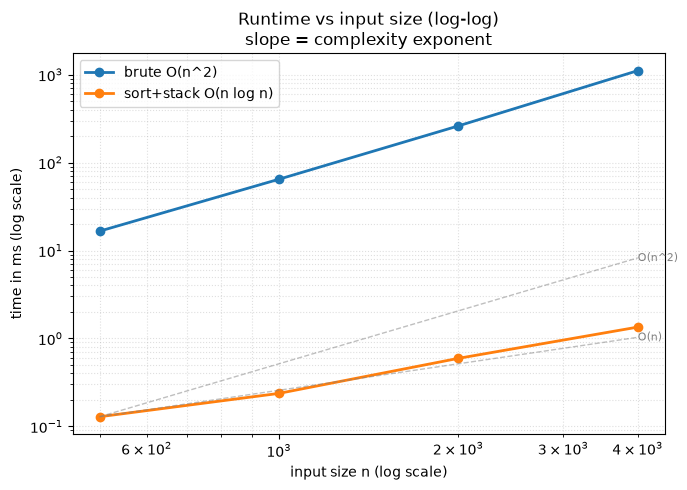

{'brute O(n^2)': [16.582417069002986,
  64.61383297573775,
  260.99174993578345,
  1109.2289160005748],
 'sort+stack O(n log n)': [0.12874999083578587,
  0.23729202803224325,
  0.5938749527558684,
  1.3461660128086805]}

In [5]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

import random

def make_worst_case(n):
    pos = list(range(n))
    random.Random(n).shuffle(pos)          # unsorted input, so the sort does real work
    return (n, pos, [1] * n)               # target = n, speed 1: no car ever catches another
solutions = {
    "brute O(n^2)": car_fleet_brute,
    "sort+stack O(n log n)": car_fleet_stack,
}
sizes = [500, 1000, 2000, 4000]

benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Monotonic Stack](README.md) — after sorting by position, the fleet arrival times form a strictly increasing stack; a car whose time would break the order (`t <= top`) merges into the fleet ahead instead of being pushed.
- **Sort first when order on a line decides the interactions.** Cars, people in a queue, buildings: sort by position, then sweep from the end that is never blocked.
- **Collapse each item to one comparable number.** Position and speed matter only through the arrival time `(target - p) / s`.
- **Signal:** "cannot pass", "catches up and moves together", "how many groups arrive", "fleets", "collisions on a line".
- **Related problems:** Daily Temperatures, Car Fleet II (collision times, also a monotonic stack), Asteroid Collision, Number of Visible People in a Queue.
- **Common pitfalls:**
  1. Sweeping from the back of the road: a rear car's fate depends on the cars ahead, so start with the car closest to the target.
  2. Using `<` instead of `<=` for the merge: catching up **exactly at the target** still counts as one fleet.
  3. Forgetting to sort: the input positions are in any order.
  4. Integer division `(target - p) // s`: it rounds times down and merges cars that never meet.